# Aula 3 — Classificação de áudio falso: SVM e Random Forest

Este notebook continua a [análise exploratória](aula-03-deteccao-audio-falso.ipynb). Compara **dois métodos em três conjuntos de atributos**, totalizando seis experimentos.

| Conjunto | Entradas | Pergunta |
|---|---|---|
| `duracao` | Somente duração (1 atributo) | Quanto conseguimos prever por uma possível particularidade do dataset? |
| `mfcc` | Média e desvio-padrão dos 20 MFCCs (40 atributos) | Qual o resultado usando apenas o perfil cepstral? |
| `completo` | MFCCs, demais atributos espectrais, baixa energia e medidas de qualidade, incluindo duração (57 atributos) | O conjunto ampliado acrescenta informação útil? |

**Métodos:** SVM com kernel RBF, precedido por padronização; e Random Forest, sem padronização. 

**Protocolo:** escolher parâmetros apenas por validação cruzada em quatro partes dentro dos 192 áudios de treino; depois avaliar as seis configurações fixadas nos 96 áudios de teste, que contêm métodos de síntese desconhecidos no treino. `spoof` é a classe positiva (1); `bonafide` é a negativa (0).

Este notebook exige as tabelas exportadas pela análise exploratória. Cada execução cria uma nova pasta de evidências; repetir a avaliação no mesmo teste não constitui um novo teste independente.

In [2]:
from pathlib import Path
import sys
import json
import hashlib
import platform
from datetime import datetime, timezone
from importlib.metadata import version
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (make_scorer, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix)

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'outros/aula-03-deteccao-audio-falso').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Abra o notebook dentro do repositório.')
BASE = ROOT / 'outros/aula-03-deteccao-audio-falso'
DATA = BASE / 'dados/subconjunto_288'
EDA = BASE / 'resultados/eda'
sys.path.insert(0, str(BASE))
from atributos_audio import extrair_arquivo

CONFIG = {'seed': 42, 'n_splits': 4, 'n_jobs': 1}
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT = BASE / 'resultados/classificacao' / RUN_ID
FIG = ROOT / 'images/aula-03/classificacao' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
FIG.mkdir(parents=True, exist_ok=False)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def salvar_figura(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Python:', sys.executable)
print('Execução:', RUN_ID)
print('Scikit-learn:', version('scikit-learn'))

Python: d:\Code\portfolio-pcs5917\.venv\Scripts\python.exe
Execução: 20261103T210643208200Z
Scikit-learn: 1.9.1


## 1. Carregar somente o treino e conferir a procedência

Unimos rótulos, atributos e qualidade por `file_id`. IDs e metadados não entram no modelo.

Também reextraímos quatro arquivos de treino para conferir a equivalência entre o processamento deste notebook e os atributos exportados pela EDA. Não há ajuste estatístico na extração: cada áudio é processado individualmente com parâmetros fixos.

In [3]:
required = ['execucao.json', 'atributos_treino.csv', 'qualidade_treino.csv', 'metadados_treino.csv']
for name in required:
    if not (EDA / name).is_file():
        raise FileNotFoundError(f'Execute a exportação da EDA antes: {name}')
eda_manifest = json.loads((EDA / 'execucao.json').read_text(encoding='utf-8'))
AUDIO_CONFIG = eda_manifest['config']
assert AUDIO_CONFIG['n_mfcc'] == 20
assert sha256(DATA / 'treino_192.csv') == eda_manifest['input_csv_sha256']['treino_192.csv']
train = pd.read_csv(DATA / 'treino_192.csv', keep_default_na=False)
exported_meta = pd.read_csv(EDA / 'metadados_treino.csv', keep_default_na=False)
pd.testing.assert_frame_equal(train.sort_values('file_id').reset_index(drop=True),
                             exported_meta.sort_values('file_id').reset_index(drop=True))
features = pd.read_csv(EDA / 'atributos_treino.csv')
quality = pd.read_csv(EDA / 'qualidade_treino.csv')
for frame in [train, features, quality]:
    assert frame.file_id.is_unique
    assert set(frame.file_id) == set(train.file_id)
assert len(train) == 192 and train.speaker_id.is_unique
assert set(train.role) == {'train'} and set(train.split) == {'train'}
assert train.label.value_counts().to_dict() == {'bonafide': 96, 'spoof': 96}
assert set(train.loc[train.label == 'spoof', 'attack']) == {f'A{i:02d}' for i in range(1, 9)}
assert all((DATA / p).is_file() for p in train.local_path)

ACOUSTIC_COLUMNS = eda_manifest['feature_columns']
QUALITY_COLUMNS = ['duration_s', 'peak', 'rms_global', 'near_clip_fraction']
MFCC_COLUMNS = [f'mfcc_{i:02d}_{stat}' for i in range(1, 21) for stat in ['mean', 'std']]
FEATURE_SETS = {
    'duracao': ['duration_s'],
    'mfcc': MFCC_COLUMNS,
    'completo': [*ACOUSTIC_COLUMNS, *QUALITY_COLUMNS],
}
assert len(ACOUSTIC_COLUMNS) == 53 and len(FEATURE_SETS['completo']) == 57
assert set(features.columns) == {'file_id', *ACOUSTIC_COLUMNS}
training = train.merge(features, on='file_id', validate='one_to_one').merge(
    quality[['file_id', *QUALITY_COLUMNS]], on='file_id', validate='one_to_one')
X_train = training[FEATURE_SETS['completo']].copy()
y_train = training['label'].map({'bonafide': 0, 'spoof': 1}).astype(int)
assert np.isfinite(X_train.to_numpy()).all()
assert not set(X_train.columns) & {'file_id', 'label', 'attack', 'gender', 'speaker_id', 'local_path'}

for label in ['bonafide', 'spoof']:
    sample = training.loc[training.label == label].sample(2, random_state=CONFIG['seed'])
    for row in sample.itertuples(index=False):
        actual = extrair_arquivo(DATA / row.local_path, AUDIO_CONFIG)
        expected = training.set_index('file_id').loc[row.file_id, FEATURE_SETS['completo']].astype(float)
        np.testing.assert_allclose([actual[c] for c in expected.index], expected.to_numpy(),
                                   rtol=1e-5, atol=1e-6)

display(pd.DataFrame([{'conjunto': name, 'atributos': len(cols)}
                     for name, cols in FEATURE_SETS.items()]))
constant = X_train.columns[X_train.nunique() == 1].tolist()
print('Extração equivalente em quatro exemplos de treino; classes e entradas conferidas.')
print('Atributos constantes no treino:', constant, '(mantidos no protocolo fixado)')

,conjunto,atributos
0,duracao,1
1,mfcc,40
2,completo,57


Extração equivalente em quatro exemplos de treino; classes e entradas conferidas.
Atributos constantes no treino: ['near_clip_fraction'] (mantidos no protocolo fixado)


## 2. Dividir o treino em quatro partes

Cada rodada usa **144 áudios para treinar e 48 para validar**, com 24 legítimos e 24 falsos na validação. Estratificamos pela classe e pelo código de ataque: cada parte contém três exemplos de cada ataque conhecido. Não usamos o código como atributo.

As seis experiências usam exatamente as mesmas divisões. Cada áudio aparece uma vez em validação, e não há locutor compartilhado entre treino e validação. Esta validação mede novos exemplos de **métodos conhecidos**, enquanto o teste final mede métodos desconhecidos.

In [4]:
strata = np.where(training.label == 'bonafide', 'bonafide', training.attack)
splitter = StratifiedKFold(n_splits=CONFIG['n_splits'], shuffle=True, random_state=CONFIG['seed'])
FOLDS = list(splitter.split(X_train, strata))
fold_assignment = np.full(len(training), -1, dtype=int)
fold_rows = []
for fold, (tr, va) in enumerate(FOLDS, start=1):
    assert len(tr) == 144 and len(va) == 48
    assert not set(training.iloc[tr].speaker_id) & set(training.iloc[va].speaker_id)
    assert y_train.iloc[va].value_counts().to_dict() == {0: 24, 1: 24}
    attack_counts = training.iloc[va].query("label == 'spoof'").attack.value_counts()
    assert len(attack_counts) == 8 and attack_counts.eq(3).all()
    fold_assignment[va] = fold
    fold_rows.append({'rodada': fold, 'treino': len(tr), 'validacao': len(va),
                      'legitimos_validacao': 24, 'falsos_validacao': 24})
assert (fold_assignment > 0).all()
training[['file_id', 'speaker_id', 'label', 'attack']].assign(
    validation_fold=fold_assignment).to_csv(OUT / 'divisoes_treino.csv', index=False)
display(pd.DataFrame(fold_rows))

,rodada,treino,validacao,legitimos_validacao,falsos_validacao
0,1,144,48,24,24
1,2,144,48,24,24
2,3,144,48,24,24
3,4,144,48,24,24


## 3. Buscar parâmetros apenas no treino

Testamos uma grade pequena e previamente definida. Na SVM, `C` controla a penalização dos erros e `gamma` o alcance da influência dos exemplos na fronteira RBF. Na floresta, variamos a profundidade máxima e o mínimo de exemplos por folha, com 200 árvores.

A padronização da SVM está em uma **Pipeline**: em cada rodada, médias e escalas são aprendidas somente nos 144 exemplos usados para treinar. A floresta não precisa dessa transformação.

**Critério de escolha:** maior acurácia balanceada média na validação. Ela é a média da taxa de acerto dos legítimos e da taxa de detecção dos falsos; prever uma única classe sempre resulta em 50%. Em empates, o GridSearchCV mantém o primeiro candidato na ordem da grade.

Também registramos precisão (quanto dos sinalizados como falsos realmente é falso), recall (quanto dos falsos foi detectado) e F1 da classe falsa. O desvio-padrão entre quatro rodadas indica variação, não um intervalo de confiança.

In [5]:
SCORING = {
    'balanced_accuracy': 'balanced_accuracy',
    'precision_spoof': make_scorer(precision_score, pos_label=1, zero_division=0),
    'recall_spoof': make_scorer(recall_score, pos_label=1, zero_division=0),
    'f1_spoof': make_scorer(f1_score, pos_label=1, zero_division=0),
}

def definir_modelo(name):
    if name == 'SVM':
        return (Pipeline([('scale', StandardScaler()), ('model', SVC(kernel='rbf'))]),
                {'model__C': [0.1, 1, 10], 'model__gamma': ['scale', 0.01, 0.1]})
    return (RandomForestClassifier(n_estimators=200, random_state=CONFIG['seed'], n_jobs=1),
            {'max_depth': [None, 5], 'min_samples_leaf': [1, 3, 6]})

searches, cv_rows, grid_frames, fold_scores = {}, [], [], []
for feature_name, columns in FEATURE_SETS.items():
    for model_name in ['SVM', 'RandomForest']:
        key = f'{feature_name}__{model_name}'
        estimator, grid = definir_modelo(model_name)
        start = perf_counter()
        search = GridSearchCV(estimator, grid, scoring=SCORING, refit='balanced_accuracy',
            cv=FOLDS, n_jobs=CONFIG['n_jobs'], error_score='raise', return_train_score=False)
        search.fit(X_train[columns], y_train)
        searches[key] = search  # best_estimator_ já foi ajustado nos 192 áudios
        idx = search.best_index_
        row = {'experimento': key, 'conjunto': feature_name, 'modelo': model_name,
               'n_atributos': len(columns), 'tempo_s': perf_counter() - start,
               'parametros': json.dumps(search.best_params_, sort_keys=True)}
        for metric in SCORING:
            row[f'{metric}_mean'] = search.cv_results_[f'mean_test_{metric}'][idx]
            row[f'{metric}_std'] = search.cv_results_[f'std_test_{metric}'][idx]
        cv_rows.append(row)
        grid_frame = pd.DataFrame(search.cv_results_)
        grid_frame.insert(0, 'experimento', key)
        grid_frames.append(grid_frame)
        for fold in range(CONFIG['n_splits']):
            fold_scores.append({'experimento': key, 'rodada': fold + 1,
                **{m: search.cv_results_[f'split{fold}_test_{m}'][idx] for m in SCORING}})
        print(f"{key}: validação {search.best_score_:.3f}; {row['tempo_s']:.1f}s", flush=True)

cv_summary = pd.DataFrame(cv_rows)
cv_summary.to_csv(OUT / 'validacao_resumo.csv', index=False)
pd.concat(grid_frames, ignore_index=True).to_csv(OUT / 'busca_parametros.csv', index=False)
pd.DataFrame(fold_scores).to_csv(OUT / 'validacao_por_rodada.csv', index=False)
display(cv_summary[['conjunto', 'modelo', 'n_atributos', 'balanced_accuracy_mean',
    'balanced_accuracy_std', 'precision_spoof_mean', 'recall_spoof_mean', 'f1_spoof_mean']].round(3))

duracao__SVM: validação 0.745; 0.7s
duracao__RandomForest: validação 0.693; 8.3s
mfcc__SVM: validação 0.932; 0.8s
mfcc__RandomForest: validação 0.891; 8.8s
completo__SVM: validação 0.943; 0.8s
completo__RandomForest: validação 0.917; 9.0s


,conjunto,modelo,n_atributos,balanced_accuracy_mean,balanced_accuracy_std,precision_spoof_mean,recall_spoof_mean,f1_spoof_mean
0,duracao,SVM,1,0.745,0.052,0.726,0.802,0.759
1,duracao,RandomForest,1,0.693,0.050,0.742,0.656,0.678
2,mfcc,SVM,40,0.932,0.009,0.951,0.917,0.931
3,mfcc,RandomForest,40,0.891,0.031,0.897,0.885,0.890
4,completo,SVM,57,0.943,0.023,0.989,0.896,0.939
5,completo,RandomForest,57,0.917,0.033,0.919,0.917,0.917


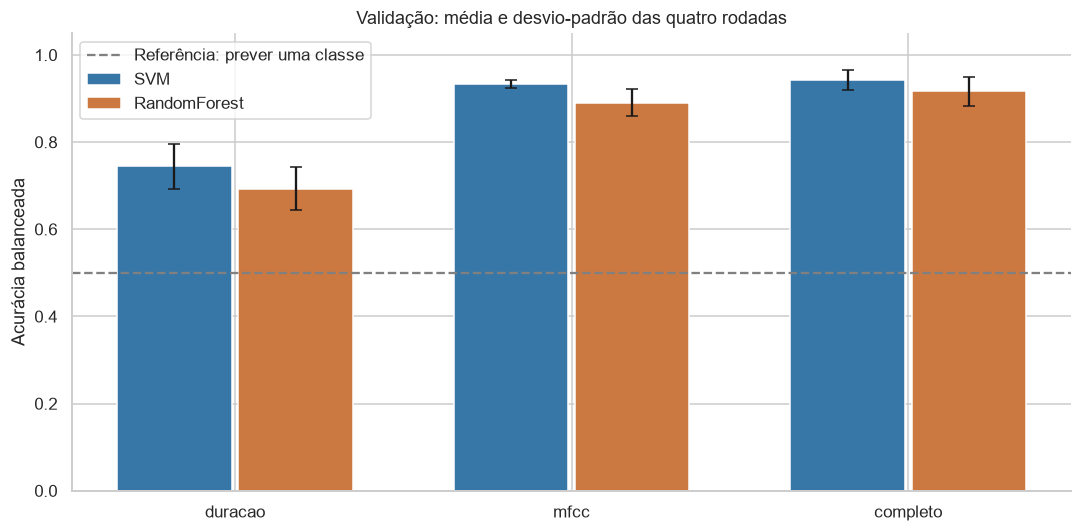

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(FEATURE_SETS))
for offset, model_name, color in [(-.18, 'SVM', '#3677a8'), (.18, 'RandomForest', '#cc7841')]:
    rows = cv_summary.loc[cv_summary.modelo == model_name].set_index('conjunto').loc[list(FEATURE_SETS)]
    ax.bar(x + offset, rows.balanced_accuracy_mean, yerr=rows.balanced_accuracy_std,
           width=.34, capsize=4, label=model_name, color=color)
ax.axhline(.5, color='gray', linestyle='--', label='Referência: prever uma classe')
ax.set(xticks=x, xticklabels=list(FEATURE_SETS), ylim=(0, 1.05),
       ylabel='Acurácia balanceada', title='Validação: média e desvio-padrão das quatro rodadas')
ax.legend()
fig.tight_layout()
salvar_figura(fig, '01_validacao')

**Anotações — validação**

- Nosso baseline, usando apenas duração, consegue uma acurácia de no máximo 75%, o que demonstra de fato a correlação da duração com a classe, um viés do dataset.
- Os MFCCs porém agregam muita informação, levando a uma acurácia de 94%. Notamos que os 40 atributos de MFCC já são suficientes para chegar numa ótima acurácia. Usar todos os 57 atributos aumenta a acurácia de maneira marginal, com 1% ou 2%.
- Também percebemos que o classificador SVM foi superior ao RandomForest nos três conjuntos durante a validação.

## 4. Fixar escolhas antes de acessar os atributos do teste

O melhor experimento de desenvolvimento é identificado **somente pela validação**. Todos os seis serão avaliados no teste para a comparação planejada; não escolheremos parâmetros, atributos ou limiares com base no teste.

In [7]:
winner = cv_summary.sort_values('balanced_accuracy_mean', ascending=False, kind='stable').iloc[0]['experimento']
protocolo = {
    'run_id': RUN_ID, 'fixed_at_utc': datetime.now(timezone.utc).isoformat(),
    'config': CONFIG, 'audio_config': AUDIO_CONFIG, 'feature_sets': FEATURE_SETS,
    'positive_class': 'spoof', 'selection_metric': 'balanced_accuracy',
    'validation': '4 folds stratified by attack/bonafide; speaker-disjoint',
    'development_winner': winner,
    'selected_parameters': {k: s.best_params_ for k, s in searches.items()},
    'grids': {name: definir_modelo(name)[1] for name in ['SVM', 'RandomForest']},
    'python': platform.python_version(),
    'packages': {p: version(p) for p in ['scikit-learn', 'numpy', 'pandas', 'librosa',
                                        'soundfile', 'scipy', 'numba', 'matplotlib', 'seaborn']},
    'input_sha256': {str(p.relative_to(ROOT)): sha256(p)
        for p in [DATA / 'treino_192.csv', EDA / 'execucao.json', EDA / 'atributos_treino.csv',
                  EDA / 'qualidade_treino.csv', BASE / 'atributos_audio.py']},
}
protocol_path = OUT / 'protocolo_antes_teste.json'
protocol_path.write_text(json.dumps(protocolo, ensure_ascii=False, indent=2), encoding='utf-8')
protocol_hash = sha256(protocol_path)
print('Melhor configuração pela validação:', winner)
print('Protocolo fixado em:', protocol_path)

Melhor configuração pela validação: completo__SVM
Protocolo fixado em: d:\Code\portfolio-pcs5917\outros\aula-03-deteccao-audio-falso\resultados\classificacao\20261103T210643208200Z\protocolo_antes_teste.json


## 5. Processar o teste com o mesmo procedimento

Somente agora carregamos os 96 exemplos reservados (48 de cada classe, seis de cada ataque A09–A16). Conferimos IDs, locutores e códigos distintos do treino. A função de extração é a mesma cuja equivalência com a EDA foi verificada no início.

In [8]:
assert sha256(protocol_path) == protocol_hash
assert sha256(DATA / 'teste_96.csv') == eda_manifest['input_csv_sha256']['teste_96.csv']
test = pd.read_csv(DATA / 'teste_96.csv', keep_default_na=False)
assert len(test) == 96 and test.file_id.is_unique and test.speaker_id.is_unique
assert set(test.role) == {'test'} and set(test.split) == {'dev'}
assert test.label.value_counts().to_dict() == {'bonafide': 48, 'spoof': 48}
assert not set(train.file_id) & set(test.file_id)
assert not set(train.speaker_id) & set(test.speaker_id)
assert set(test.loc[test.label == 'spoof', 'attack']) == {f'A{i:02d}' for i in range(9, 17)}
test_rows = []
for i, row in enumerate(test.itertuples(index=False), start=1):
    test_rows.append({'file_id': row.file_id, **extrair_arquivo(DATA / row.local_path, AUDIO_CONFIG)})
    if i % 24 == 0:
        print(f'Extração do teste: {i}/{len(test)}', flush=True)
test_features = pd.DataFrame(test_rows)
testing = test.merge(test_features, on='file_id', validate='one_to_one')
X_test = testing[FEATURE_SETS['completo']]
y_test = testing.label.map({'bonafide': 0, 'spoof': 1}).astype(int)
assert np.isfinite(X_test.to_numpy()).all()
test_features.to_csv(OUT / 'atributos_teste.csv', index=False)
print('Atributos de teste preparados, sem ajuste dos modelos.')

Extração do teste: 24/96
Extração do teste: 48/96
Extração do teste: 72/96
Extração do teste: 96/96
Atributos de teste preparados, sem ajuste dos modelos.


## 6. Avaliação final das seis configurações fixadas

Além das métricas gerais, mostramos a taxa de legítimos sinalizados incorretamente (**falso positivo**) e a taxa de falsos que passaram como legítimos (**falso negativo**). As matrizes mostram contagens: linhas são classes reais e colunas são previsões.

O teste tem apenas 48 exemplos por classe: um erro altera o recall da respectiva classe em cerca de 2,1 pontos percentuais. Pequenas diferenças entre modelos devem ser interpretadas com cautela.

,conjunto,modelo,balanced_accuracy,precision_spoof,recall_spoof,f1_spoof,false_positive_rate,false_negative_rate
0,duracao,SVM,0.500,0.500,1.000,0.667,1.000,0.000
1,duracao,RandomForest,0.500,0.500,1.000,0.667,1.000,0.000
2,mfcc,SVM,0.677,0.870,0.417,0.563,0.062,0.583
3,mfcc,RandomForest,0.740,0.829,0.604,0.699,0.125,0.396
4,completo,SVM,0.531,1.000,0.062,0.118,0.000,0.938
5,completo,RandomForest,0.781,0.865,0.667,0.753,0.104,0.333


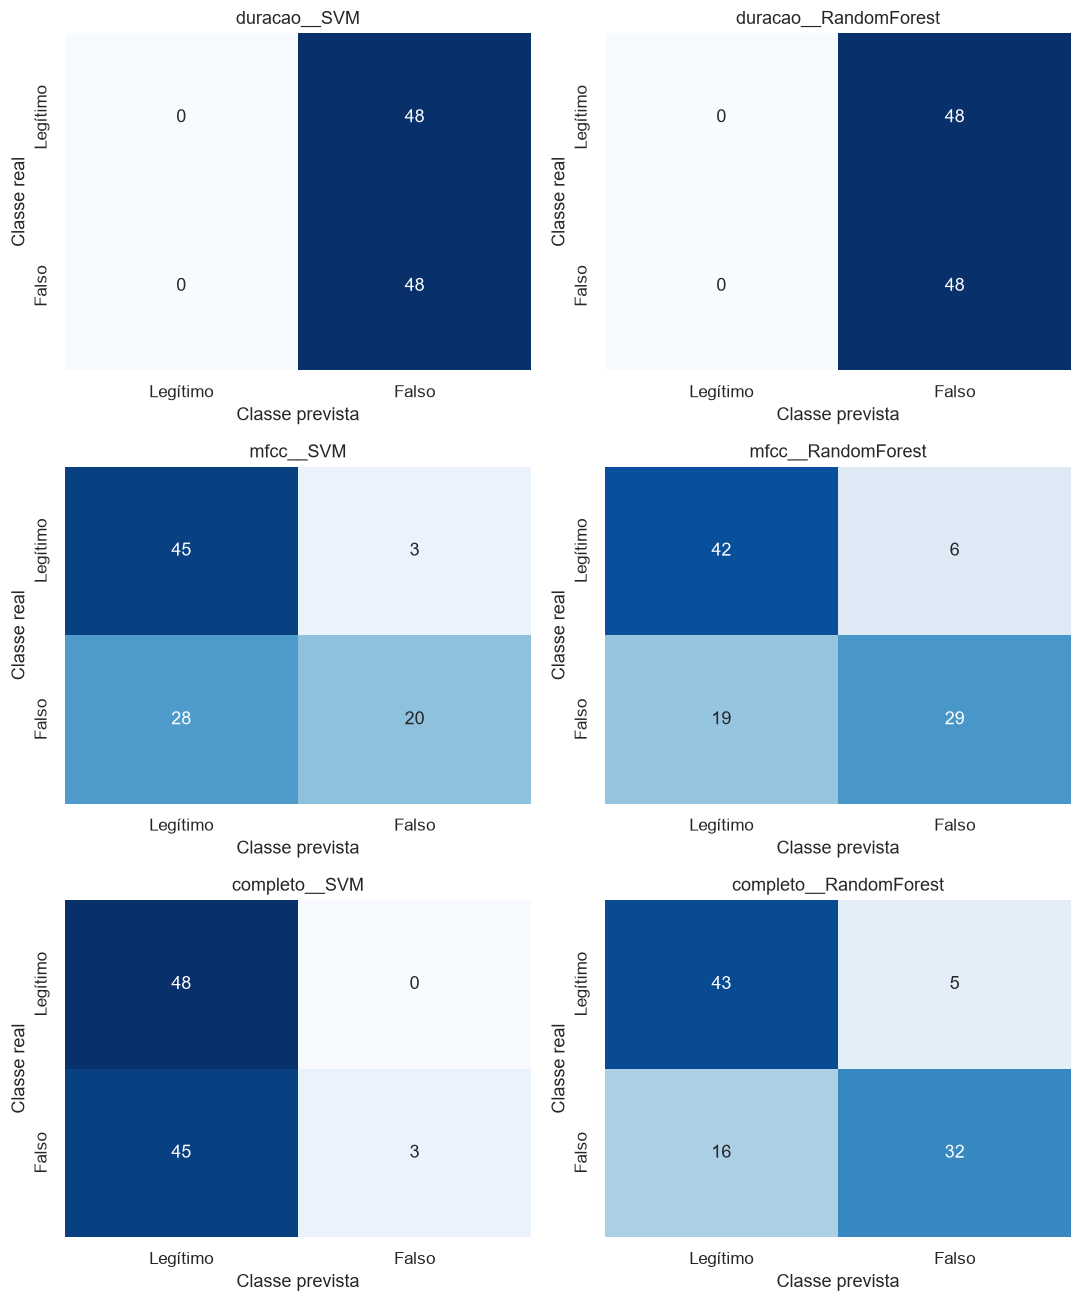

In [9]:
test_rows, prediction_frames, matrices = [], [], {}
for key, search in searches.items():
    feature_name, model_name = key.split('__')
    prediction = search.best_estimator_.predict(X_test[FEATURE_SETS[feature_name]])
    tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
    matrices[key] = np.array([[tn, fp], [fn, tp]])
    test_rows.append({
        'experimento': key, 'conjunto': feature_name, 'modelo': model_name,
        'accuracy': accuracy_score(y_test, prediction),
        'balanced_accuracy': balanced_accuracy_score(y_test, prediction),
        'precision_spoof': precision_score(y_test, prediction, zero_division=0),
        'recall_spoof': recall_score(y_test, prediction, zero_division=0),
        'f1_spoof': f1_score(y_test, prediction, zero_division=0),
        'false_positive_rate': fp / (tn + fp), 'false_negative_rate': fn / (tp + fn),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    })
    predictions = testing[['file_id', 'label', 'attack', 'speaker_id', 'gender']].copy()
    predictions.insert(0, 'experimento', key)
    predictions['y_true'] = y_test.to_numpy()
    predictions['y_pred'] = prediction
    predictions['predicted_label'] = np.where(prediction == 1, 'spoof', 'bonafide')
    predictions['correct'] = prediction == y_test.to_numpy()
    prediction_frames.append(predictions)

test_summary = pd.DataFrame(test_rows)
predictions = pd.concat(prediction_frames, ignore_index=True)
test_summary.to_csv(OUT / 'teste_metricas.csv', index=False)
predictions.to_csv(OUT / 'teste_predicoes.csv', index=False)
display(test_summary[['conjunto', 'modelo', 'balanced_accuracy', 'precision_spoof',
    'recall_spoof', 'f1_spoof', 'false_positive_rate', 'false_negative_rate']].round(3))

fig, axes = plt.subplots(3, 2, figsize=(10, 12))
for ax, (key, matrix) in zip(axes.flat, matrices.items()):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', vmin=0, vmax=48,
        cbar=False, xticklabels=['Legítimo', 'Falso'], yticklabels=['Legítimo', 'Falso'], ax=ax)
    ax.set(title=key, xlabel='Classe prevista', ylabel='Classe real')
fig.tight_layout()
salvar_figura(fig, '02_matrizes_confusao')

## 7. Comparar validação, teste e ataques desconhecidos

,Experimento,Validação média (%),Teste (%),Teste − validação (p.p.)
0,duracao__SVM,74.5,50.0,-24.5
1,duracao__RandomForest,69.3,50.0,-19.3
2,mfcc__SVM,93.2,67.7,-25.5
3,mfcc__RandomForest,89.1,74.0,-15.1
4,completo__SVM,94.3,53.1,-41.1
5,completo__RandomForest,91.7,78.1,-13.5


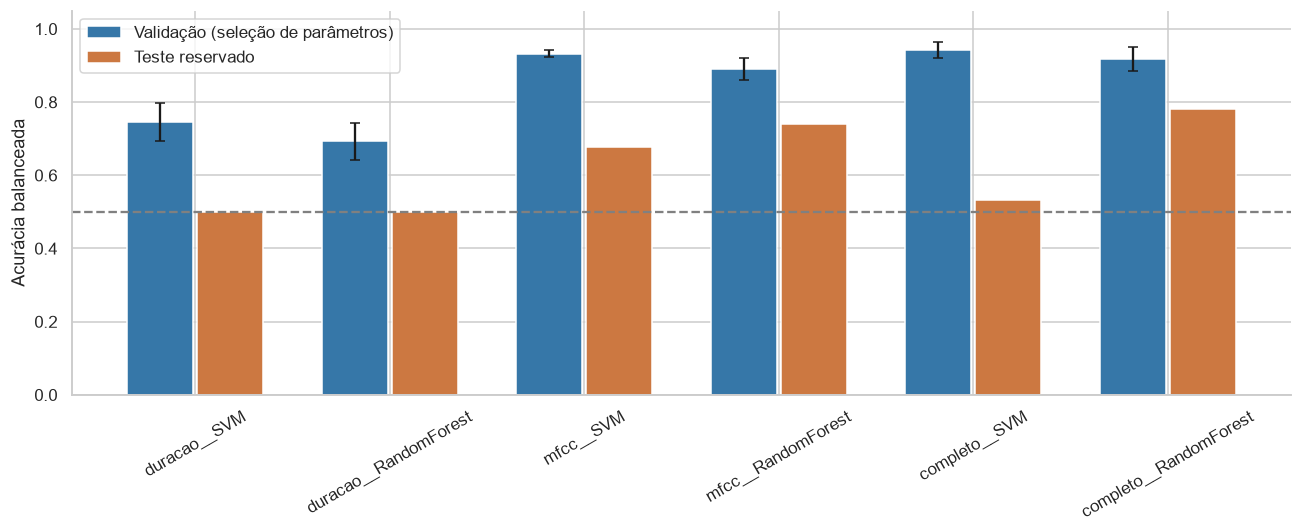

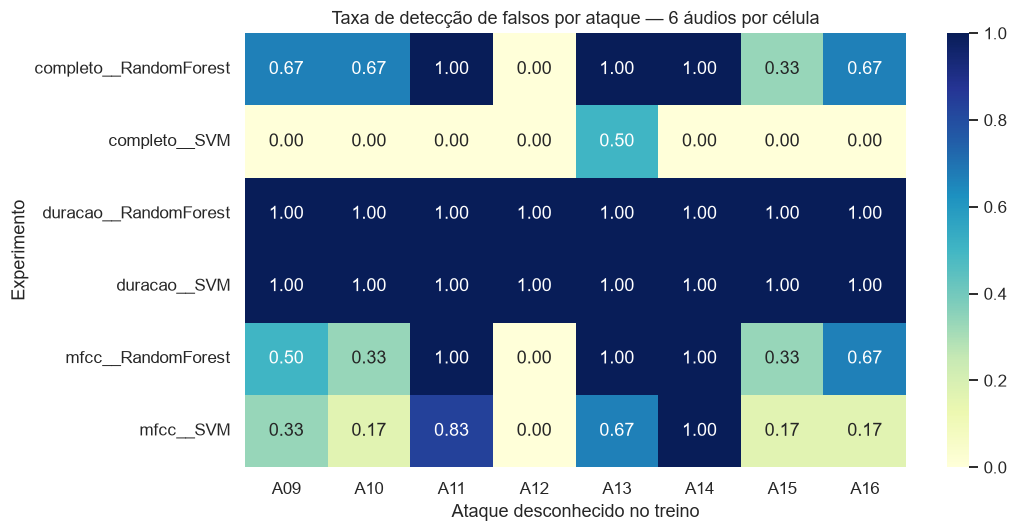

In [10]:
comparison = cv_summary[['experimento', 'balanced_accuracy_mean', 'balanced_accuracy_std']].merge(
    test_summary[['experimento', 'balanced_accuracy']], on='experimento', validate='one_to_one')
comparison['test_minus_validation'] = comparison.balanced_accuracy - comparison.balanced_accuracy_mean
# Apresentação em porcentagem e pontos percentuais.
comparison_display = comparison.drop(columns='balanced_accuracy_std').rename(columns={
    'experimento': 'Experimento',
    'balanced_accuracy_mean': 'Validação média (%)',
    'balanced_accuracy': 'Teste (%)',
    'test_minus_validation': 'Teste − validação (p.p.)',
})
comparison_display.iloc[:, 1:] = comparison_display.iloc[:, 1:] * 100
comparison_display.to_csv(OUT / 'validacao_vs_teste.csv', index=False)
display(comparison_display.round(1))
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(comparison))
ax.bar(x - .18, comparison.balanced_accuracy_mean, yerr=comparison.balanced_accuracy_std,
       width=.34, capsize=3, label='Validação (seleção de parâmetros)', color='#3677a8')
ax.bar(x + .18, comparison.balanced_accuracy, width=.34, label='Teste reservado', color='#cc7841')
ax.axhline(.5, color='gray', linestyle='--')
ax.set(xticks=x, xticklabels=comparison.experimento, ylim=(0, 1.05), ylabel='Acurácia balanceada')
ax.tick_params(axis='x', rotation=30)
ax.legend()
fig.tight_layout()
salvar_figura(fig, '03_validacao_vs_teste')

by_attack = predictions.loc[predictions.label == 'spoof'].groupby(
    ['experimento', 'attack']).agg(n=('correct', 'size'),
    detectados=('y_pred', 'sum'), recall_spoof=('y_pred', 'mean')).reset_index()
assert by_attack['n'].eq(6).all()
by_attack.to_csv(OUT / 'teste_por_ataque.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(by_attack.pivot(index='experimento', columns='attack', values='recall_spoof'),
    annot=True, fmt='.2f', vmin=0, vmax=1, cmap='YlGnBu', ax=ax)
ax.set(title='Taxa de detecção de falsos por ataque — 6 áudios por célula',
       xlabel='Ataque desconhecido no treino', ylabel='Experimento')
fig.tight_layout()
salvar_figura(fig, '04_deteccao_por_ataque')

## 8. Análise dos resultados

**Anotações — classificação**

1. O melhor classificador na validação foi o [Completo_SVM], porém ele performou de maneira péssima no teste (-41%). Por outro lado, o [Completo_RandomForest] conseguiu generalizar melhor, perdendo apenas (14%). Como o teste usa outros tipos de ataque, podem concluir que o SVM se especializou mais em reconhecer os ataques específicos do treinamento, enquanto o Random Forest conseguiu perceber melhor o que é uma voz humana.
2. A correlação no baseline de validação não se sustentou para este novo dataset de teste.
3. MFCCs e atributos completos melhoraram a detecção? Com que taxa de falsos positivos?
4. Podemos concluir que treinar para uma classe de ataques não garante generalização para outros ataques. O ideal é treinar com amostrar de todos os ataques possível.

In [11]:
assert sha256(protocol_path) == protocol_hash, 'O protocolo mudou depois de fixado.'
final_manifest = {
    'run_id': RUN_ID, 'finished_at_utc': datetime.now(timezone.utc).isoformat(),
    'protocol_sha256': protocol_hash, 'test_csv_sha256': sha256(DATA / 'teste_96.csv'),
    'train_rows': len(training), 'test_rows': len(testing), 'experiments': len(searches),
    'development_winner': winner,
    'audio_sha256': {row.file_id: sha256(DATA / row.local_path)
        for row in pd.concat([train, test]).itertuples(index=False)},
    'output_csv_sha256': {p.name: sha256(p) for p in OUT.glob('*.csv')},
}
(OUT / 'execucao.json').write_text(json.dumps(final_manifest, ensure_ascii=False, indent=2), encoding='utf-8')
print('CSV e registros:', OUT)
print('Figuras:', FIG)
print('Escolha prévia pela validação:', winner)
print('Salve o notebook com suas saídas e anotações.')

CSV e registros: d:\Code\portfolio-pcs5917\outros\aula-03-deteccao-audio-falso\resultados\classificacao\20261103T210643208200Z
Figuras: d:\Code\portfolio-pcs5917\images\aula-03\classificacao\20261103T210643208200Z
Escolha prévia pela validação: completo__SVM
Salve o notebook com suas saídas e anotações.


## Referências

- [Notebook exploratório e seleção dos dados](aula-03-deteccao-audio-falso.ipynb).
- [Scikit-learn: busca de parâmetros e validação cruzada](https://scikit-learn.org/stable/modules/grid_search.html).
- [Pipeline e prevenção de vazamento de dados](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
- [SVM](https://scikit-learn.org/stable/modules/svm.html) e [Random Forest](https://scikit-learn.org/stable/modules/ensemble.html#forest).
- [Acurácia balanceada](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html).
- [Descrição do ASVspoof 5](https://doi.org/10.1016/j.csl.2025.101825).